### Social Media Impact Analysis
We will load the dataset, perform exploratory data analysis, build a classification model to predict user impact class, and visualize results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load the dataset
df = pd.read_csv('/content/Social_media_impact_on_life.csv')

# Quick EDA
print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())

Dataset Shape: (4500, 16)

Dataset Columns:
['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact']


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial



Missing values:
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64


In [2]:
# We will dynamically identify or create a target variable for classification if there isn't an obvious binary/multiclass categorical target.
# Let's clean the columns and automatically select a likely target or construct a binary target for classification.
target_col = None
for col in df.columns:
    if 'impact' in col.lower() or 'satisfaction' in col.lower() or 'outcome' in col.lower() or 'class' in col.lower():
        target_col = col
        break

if not target_col:
    # Fallback to the last column if no matching keyword is found
    target_col = df.columns[-1]

print(f"Selected target column for classification: {target_col}")

# Drop rows with missing targets
df = df.dropna(subset=[target_col])

# Fill remaining numeric nulls with median, and categorical with mode
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')
    else:
        df[col] = df[col].fillna(df[col].median())

# Encode categorical variables
encoders = {}
for col in df.columns:
    if df[col].dtype == 'object':
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        encoders[col] = le

# Separate Features and Target
X = df.drop(columns=[target_col])
y = df[target_col]

# Split train and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Selected target column for classification: Overall_Impact
Training set shape: (3600, 15)
Testing set shape: (900, 15)


In [3]:
# Train a Random Forest Classifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)

# Output Accuracy and Performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9844

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       754
           1       1.00      0.88      0.93        32
           2       0.92      0.96      0.94       114

    accuracy                           0.98       900
   macro avg       0.97      0.94      0.96       900
weighted avg       0.98      0.98      0.98       900



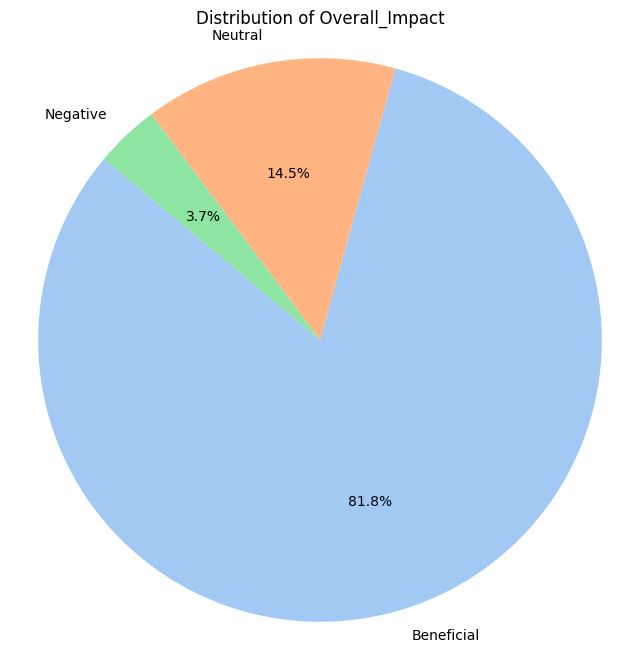

In [4]:
# Draw a pie chart of the target variable distribution
target_counts = df[target_col].value_counts()
labels = target_counts.index

# Map back to original categories if a LabelEncoder was used
if target_col in encoders:
    labels = encoders[target_col].inverse_transform(target_counts.index)

plt.figure(figsize=(8, 8))
plt.pie(target_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title(f'Distribution of {target_col}')
plt.axis('equal')
plt.show()

In [5]:
import pickle

# Save the model file
model_filename = 'social_media_impact_rf_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(clf, file)

# Save the encoders too so that future inputs can be preprocessed identically
encoders_filename = 'label_encoders.pkl'
with open(encoders_filename, 'wb') as file:
    pickle.dump(encoders, file)

print(f"Successfully saved the trained classifier to: {model_filename}")
print(f"Successfully saved the label encoders to: {encoders_filename}")

Successfully saved the trained classifier to: social_media_impact_rf_model.pkl
Successfully saved the label encoders to: label_encoders.pkl
